
# Géométrie, modèles de projection, calibration et première reprojection


**Compétences visées :**
1. Distinguer pose extrinsèque, matrice intrinsèque et loi de projection.
2. Déduire les cinq modèles classiques et comprendre leurs domaines de validité.
3. Comparer des images d'une même scène virtuelle selon différents modèles.
4. Interpréter les quatre coefficients de distorsion fisheye d'OpenCV.
5. Résoudre et diagnostiquer une calibration par minimisation d'erreur de reprojection.
6. Comprendre pourquoi une calibration monoculaire donne des **directions**, et non une profondeur métrique.
7. Effectuer une première reprojection vers des vues perspective, cylindrique et équirectangulaire.

```bash
python -m pip install numpy matplotlib opencv-python scipy notebook
jupyter notebook
```

**Conventions adoptées partout :**
- Repère caméra : centre optique à l'origine, axe optique **+Z**, **+X** vers la droite de l'image, **+Y** vers le bas.
- Un point 3D est $X_c=(X,Y,Z)^\top$ (mètres, sauf spécification contraire).
- Les pixels sont $(u,v)$ ; $u$ vers la droite, $v$ vers le bas.
- Les angles sont en **radians** dans les équations et dans le code, sauf indication « degrés ».
- Une **caméra centrale et radialement symétrique** est supposée pour les dérivations fisheye. C'est un modèle de caméra, pas une propriété parfaite de toutes les optiques réelles.
- Aucune projection ne peut reconstruire des directions **non observées** par le capteur.

In [20]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import cv2
import pip

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.20})
RNG = np.random.default_rng(2026)

# I - D'un point 3D à un pixel

Pour projeter un point 3D sur une image, on distingue **trois étapes** : Changement de repère,  Projection géométrique, Coordonnées en pixels.

Un même point 3D possède des coordonnées différentes selon le repère choisi.
- **Repère du damier** : origine et axes fixés au damier.
- **Repère de la caméra** : origine au centre optique, axes liés à la caméra.

Pour un même point $P$, on note 
- $P_d \in \mathbb{R}^3$ : ses coordonnées dans le repère du damier.
- $P_c \in \mathbb{R}^3$ : ses coordonnées dans le repère de la caméra.

Le changement de repère s'écrit avec $R \in SO(3)$ (rotation), $t \in \mathbb{R}^3$ (position de l'origine du damier, exprimée dans le repère caméra).
$$
P_c = RP_d + t
$$
**Les extrinsèques $(R,t)$ décrivent donc la position et l'orientation du damier par rapport à la caméra.**

Puis, on projette le point $P_c$ sur l'image 
$$
P_c \in \mathbb{R}^3
\quad \longrightarrow \quad
(x',y') \in \mathbb{R}^2
$$
La projection dépend du **modèle de caméra** : perspective classique ou fisheye (équidistant, équistéréographique, etc.).

Les coordonnées normalisées $(x',y')$ sont converties en pixels $(u,v)$ :

$$
u = f_x x' + c_x \qquad v = f_y y' + c_y
$$

Sous forme matricielle, avec 
- $f_x,f_y > 0$ : focales exprimées en pixels.
- $(c_x,c_y)$ : point principal, généralement proche du centre de l'image.
- $K$ : matrice des **paramètres intrinsèques**, supposant ici un cisaillement nul.

$$
\begin{pmatrix}u\\v\\1\end{pmatrix}
=
\underbrace{
\begin{pmatrix}
f_x & 0 & c_x\\
0 & f_y & c_y\\
0 & 0 & 1
\end{pmatrix}
}_{K}
\begin{pmatrix}x'\\y'\\1\end{pmatrix}
$$

---

**À retenir :**

1. **Extrinsèques $(R,t)$** : dans quel repère exprime-t-on le point ?
2. **Projection** : comment passe-t-on de la 3D à la 2D ?
3. **Intrinsèques $K$** : où se trouve le point en pixels ?

<img src="img/KjszQ_d1wj-lyncibGa7J2uRfB1B2X7Ubx-rJL75piYVVb-17HLlZe4Uf13mheShJ5d2h2OscYKmSLcN6Ri5bI6WMGbrFxwQ7PUDz42TkKQ5KabLVb_TbDpEEe5pF3UZE-0OUkywGfRtI3B7utbbZPxxHlr1sCD6khZr-GoHYlrtwFIAYEzNkAhn7-BpYGyK.jpg" style="width: 25%;">

<img src="img/OffWhzfKcWSNlKHUAJOqkoWImuqpiADU4L8lCDisaYeYkmunTSGWxTtcaEacWVihZjULEzcEn8KDh2QpwTAEg97eQ4aLOHm46UeAS6Z1aVPwfw3QkrhsThsXwDZcZqmyKuflTfIHiabb59AZI5_Zuar85BQu6Obtz5MFIeAWmen1mtZWB3Nv6HE6li30yC37.jpg" style="width: 25%;">

## Caméra perspective

On place un plan image virtuel devant le centre optique, à distance focale $f>0$. Pour un point $X_c=(X,Y,Z)$ avec $Z>0$, un rayon issu de l'origine a la paramétrisation $\lambda(X,Y,Z)$.

L'intersection avec le plan $z=f$ est atteinte lorsque $\lambda Z=f$. Donc $\lambda=f/Z$, $x_f=f\frac XZ$, $y_f=f\frac YZ$?

C'est exactement le théorème des triangles semblables. Avec les coordonnées **normalisées** $x=X/Z$ et $y=Y/Z$, on obtient :

$$\boxed{u=f_x\frac XZ+c_x,\qquad v=f_y\frac YZ+c_y.}$$

### Projection perspective : matrice $P$ et angle $\theta$

Pour une caméra **pinhole idéale**, on regroupe les extrinsèques $(R,t)$ et les intrinsèques $K$ dans une seule matrice :${P=K[R\mid t]\in\mathbb R^{3\times4}}$
Pour projeter un point 3D $X_w=(X,Y,Z)^\top$ :
$$
\begin{pmatrix}a\\b\\c\end{pmatrix}
=P\begin{pmatrix}X\\Y\\Z\\1\end{pmatrix}
\qquad\Longrightarrow\qquad
\boxed{u=\frac ac,\quad v=\frac bc}
$$

Le **$1$ ajouté** permet d'intégrer la translation $t$ dans la multiplication matricielle : ce sont les *coordonnées homogènes*. La **division par $c$** correspond à la division par la profondeur dans le repère caméra.
La projection n'est donc pas linéaire au sens habituel, car elle nécessite une division. La matrice $P$ permet néanmoins de l'écrire simplement en coordonnées homogènes.
**Propriété :** en projection perspective idéale, les droites 3D se projettent généralement en droites 2D, contrairement au fisheye où elles peuvent apparaître courbées.


Considérons un rayon faisant un angle $\theta$ avec l'axe optique de la caméra. Sa projection se trouve à une distance $r$ du point principal :
${r=f\tan\theta}$ où $f$ est la focale, supposée identique horizontalement et verticalement (exprimée en pixels).

Lorsque $\theta\to90^\circ$, alors $r\to+\infty$. Une projection perspective ne peut pas représenter un champ de vision de $180^\circ$ sur une image finie.

Une caméra **fisheye équidistante idéale** utilise au contraire $r=f\theta$ La distance reste alors finie à $90^\circ$, ce qui permet de représenter un champ de vision beaucoup plus large.

La matrice $P$ décrit la projection **pinhole** idéale

# II - Les familles de projections fisheye

Pour un point $X_c\neq0$, on définit sa **direction unitaire**  $d=\frac{X_c}{\|X_c\|}$
Ses angles sphériques relativement à l'axe optique sont 

$$\theta=\operatorname{atan2}\!\left(\sqrt{X^2+Y^2},Z\right)\in[0,\pi],\qquad
\varphi=\operatorname{atan2}(Y,X).$$

Lorsque $\sqrt{X^2+Y^2}>0$, $d=(\sin\theta\cos\varphi,\ \sin\theta\sin\varphi,\ \cos\theta)$.



### Projection radiale : du point 3D à l'image 2D

Sur une image 2D, on peut repérer un point par :
- $s$ : sa distance au centre de l'image (en coordonnées normalisées).
- $\varphi$ : son orientation autour de ce centre.

Par coordonnées polaires: $x'=s\cos\varphi$, $y'=s\sin\varphi$

Comment déterminer $s$ à partir d'un point 3D ? Depuis la caméra, ce point est observé sous un angle $\theta$ par rapport à l'axe optique. Sa distance au centre de l'image dépend alors du **modèle de projection**.
On note cette relation $s=q(\theta)$, d'où
$$
{x'=q(\theta)\cos\varphi,\qquad y'=q(\theta)\sin\varphi}
$$

### Les cinq principaux modèles de projection

La fonction $q$ n'est **pas choisie arbitrairement** : chaque modèle correspond à une construction géométrique ou à une propriété que l'on souhaite préserver.

| Modèle | $q(\theta)$ | Origine géométrique |
|---|---|---|
| Perspective | $\tan\theta$ | Intersection d'un rayon avec un plan |
| Équidistant | $\theta$ | Distance proportionnelle à l'angle |
| Équisolide | $2\sin(\theta/2)$ | Conservation des rapports d'aires et d'angles solides |
| Stéréographique | $2\tan(\theta/2)$ | Projection d'une sphère préservant localement les angles |
| Orthographique | $\sin\theta$ | Projection perpendiculaire d'une sphère sur un plan |

Ces fonctions possèdent des propriétés communes près de l'axe optique :

$$
q(0)=0,\qquad q(\theta)\approx\theta
\quad\text{pour }\theta\approx0.
$$

Elles sont aussi régulières et croissantes sur leur domaine de projection utilisable, ce qui permet d'associer sans ambiguïté un rayon image à un angle d'observation.


**En pratique, un objectif fisheye réel ne suit pas nécessairement exactement l'un de ces modèles : la calibration permet d'estimer sa loi de projection et ses écarts au modèle idéal.**

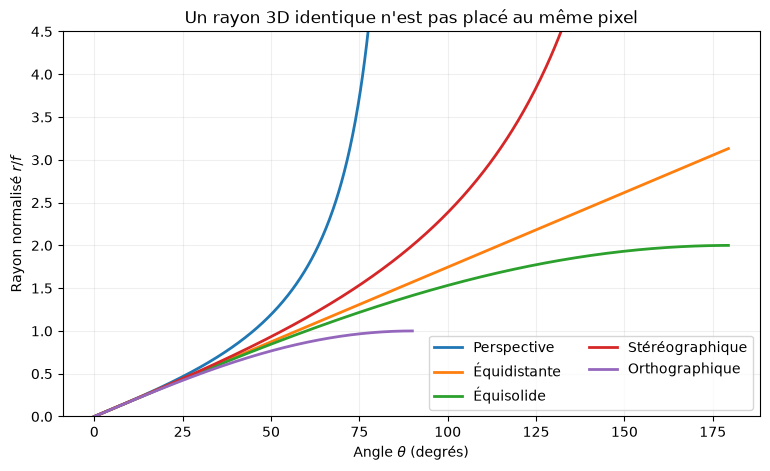

In [21]:
# Lois radiales normalisées q(theta) = r/f, sur leur domaine physiquement interprétable.
def q_of_theta(theta, model, D=None):
    """Loi sans dimension q(theta), theta en radians, vectorisée."""
    t = np.asarray(theta, dtype=np.float64)
    if model == "perspective":
        return np.tan(t)
    if model == "equidistant":
        return t
    if model == "equisolid":
        return 2.0 * np.sin(t / 2.0)
    if model == "stereographic":
        return 2.0 * np.tan(t / 2.0)
    if model == "orthographic":
        return np.sin(t)
    if model == "opencv":
        if D is None:
            raise ValueError("D doit être spécifié pour le modèle OpenCV")
        k1, k2, k3, k4 = np.asarray(D, dtype=float).ravel()
        return t * (1 + k1*t**2 + k2*t**4 + k3*t**6 + k4*t**8)
    raise ValueError(f"Modèle inconnu : {model}")

MODELS = {
    "perspective": "Perspective",
    "equidistant": "Équidistante",
    "equisolid": "Équisolide",
    "stereographic": "Stéréographique",
    "orthographic": "Orthographique",
}
limits = {"perspective": np.pi / 2 - 1e-2,
          "equidistant": np.pi - 1e-2,
          "equisolid": np.pi - 1e-2,
          "stereographic": np.pi - 1e-2,
          "orthographic": np.pi / 2}
fig, ax = plt.subplots(figsize=(9, 5))
for name, label in MODELS.items():
    end = min(np.deg2rad(180), limits[name])
    t = np.linspace(0, end, 450)
    y = q_of_theta(t, name)
    y[y > 5] = np.nan  # évite un axe illisible à l'asymptote perspective
    ax.plot(np.rad2deg(t), y, label=label, lw=2)
ax.set(xlabel=r"Angle $\theta$ (degrés)", ylabel=r"Rayon normalisé $r/f$",
       title="Un rayon 3D identique n'est pas placé au même pixel")
ax.set_ylim(0, 4.5)
ax.legend(ncol=2)
plt.show()


## 5 - Que déforment réellement les projections ?

Projeter les directions d'une sphère sur une image plane modifie nécessairement certaines propriétés géométriques : **distances, surfaces ou angles**. Chaque modèle de projection privilégie une propriété différente.
On cherche à savoir quelle **surface sur l'image** correspond à une petite portion du champ de vision.

Sur l'image, considérons une petite portion d'anneau de rayon $r$, son épaisseur est $dr$, sa longueur tangentielle est $r\,d\varphi$ (longueur d'arc $=$ rayon $\times$ angle).
Son aire infinitésimale est donc
$$
dA=\underbrace{dr}_{\text{épaisseur}}\times\underbrace{r\,d\varphi}_{\text{longueur d'arc}}
=r\,dr\,d\varphi = dA=r(\theta)r'(\theta)\,d\theta\,d\varphi
$$

Sur la sphère unité, on sait que
$d\Omega=\sin\theta\,d\theta\,d\varphi$. 
D'où le rapport mesure **la surface de l'image attribuée à une unité d'angle solide**, localement,
$$
\frac{dA}{d\Omega}=\frac{r(\theta)r'(\theta)}{\sin\theta}
$$

### 5.2 - Équisolide : conservation des surfaces

Pour $r(\theta)=2f\sin(\theta/2)$ :

$$
\frac{dA}{d\Omega}
=\frac{2f\sin(\theta/2)\,f\cos(\theta/2)}{\sin\theta}
=\boxed{f^2}
$$

**Interprétation :** le rapport est constant. Deux petites régions couvrant le même angle solide occupent la même aire sur l'image, même si elles se trouvent à des angles $\theta$ différents.

En revanche, leurs **formes peuvent être déformées** : un petit cercle peut devenir une ellipse de même aire.

### 5.3 - Équidistante : conservation des distances angulaires radiales

Pour $r(\theta)=f\theta$ :

$$
\boxed{\frac{dA}{d\Omega}=f^2\frac{\theta}{\sin\theta}}
$$

Ce rapport augmente avec $\theta$ : une même portion d'angle solide occupe davantage de surface lorsqu'elle est éloignée de l'axe optique.

En revanche, puisque $dr=f\,d\theta$, des variations identiques de $\theta$ produisent toujours des déplacements radiaux identiques sur l'image.

**Interprétation :** on préserve l'échelle angulaire **depuis le centre**, mais ni les aires ni toutes les distances entre directions quelconques.

### 5.4 - Stéréographique : conservation des angles locaux

Pour préserver localement les angles entre deux courbes, on doit étirer les petites régions **autant radialement que tangentiellement**.

Les facteurs d'étirement sont :
- **Radial :** $r'(\theta)$, déplacement sur l'image pour une variation $d\theta$.
- **Tangentiel :** $r(\theta)/\sin\theta$, rapport des longueurs dans la direction $\varphi$ sur l'image et sur la sphère.

On impose donc leur égalité :

$$
r'(\theta)=\frac{r(\theta)}{\sin\theta}
$$

C'est une **équation différentielle**. En séparant les variables :
$
\frac{dr}{r}=\frac{d\theta}{\sin\theta}
\quad\Longrightarrow\quad
\ln r=\ln\tan\frac{\theta}{2}+C
$ et on obtient $r(\theta)=C_0\tan\frac{\theta}{2}$

Avec la condition $r(\theta)\sim f\theta$ près de l'axe optique
$$
\boxed{r(\theta)=2f\tan\frac{\theta}{2}}
$$

**Interprétation :** l'étirement est identique dans toutes les directions locales. Un petit cercle reste donc localement circulaire, mais sa taille peut changer. Les angles sont préservés, **pas les surfaces**.

### 5.5 - Et les autres modèles ?

- **Perspective** ($r=f\tan\theta$) : conserve les droites de la scène, mais étire fortement les régions proches de $90^\circ$.
- **Orthographique fisheye** ($r=f\sin\theta$) : comprime les variations radiales près de $90^\circ$, jusqu'à les écraser localement dans cette direction.

---

**Bilan :** aucune projection ne conserve toute la géométrie de la sphère.

| Modèle | Propriété privilégiée |
|---|---|
| Équisolide | Aires proportionnelles aux angles solides |
| Équidistante | Distances angulaires radiales |
| Stéréographique | Angles entre courbes, localement |
| Perspective | Droites |
| Orthographique | Projection perpendiculaire de la sphère des directions |

Ces propriétés décrivent les **projections idéales**. Une caméra fisheye réelle peut présenter des écarts supplémentaires, identifiés lors de la calibration.


## 8 - Expérience 1 : une même scène 3D sous cinq projections

Nous construisons une **scène filaire 3D** (sol, grille frontale, arêtes d'un cube). Tous les pixels de chaque figure proviennent des **mêmes points 3D** ; seule la projection change.

Cela rend la comparaison plus rigoureuse qu'une juxtaposition de photos prises avec des appareils différents.

**Prédictions :**
- la projection perspective conserve les segments rectilignes (quand ils sont visibles) ;
- les projections fisheye courbent en général les segments ne passant pas par le centre optique ;
- les bords n'utilisent pas le même espace image selon $q(\theta)$ ;
- les modèles n'ont pas tous le même domaine angulaire admissible.

In [22]:
def project_dirs(directions, K, model="equidistant", D=None,
                 theta_max=np.deg2rad(95), image_size=None):
    """Directions [...,3] -> pixels [...,2] + masque visible.

    θ via atan2 permet d'exprimer des modèles mathématiques >90°.
    Le projectPoints fisheye d'OpenCV est surtout utilisé ici sur Z>0.
    """
    d = np.asarray(directions, dtype=np.float64)
    K = np.asarray(K, dtype=np.float64)
    norm = np.linalg.norm(d, axis=-1)
    safe = norm > 1e-12
    unit = d / np.where(safe, norm, 1)[..., None]
    x, y, z = unit[..., 0], unit[..., 1], unit[..., 2]
    theta = np.arctan2(np.hypot(x, y), z)
    phi = np.arctan2(y, x)
    with np.errstate(invalid="ignore", divide="ignore", over="ignore"):
        q = q_of_theta(theta, model, D)
        xp, yp = q * np.cos(phi), q * np.sin(phi)
    uv = np.stack((K[0,0]*xp + K[0,2], K[1,1]*yp + K[1,2]), axis=-1)
    valid = safe & (theta <= theta_max) & np.isfinite(uv).all(axis=-1)
    if model == "perspective":
        valid &= theta < np.pi/2 - 1e-6
    if model == "orthographic":
        valid &= theta <= np.pi/2  # autrement la projection serait ambiguë
    if image_size is not None:
        w, h = image_size
        valid &= (uv[...,0]>=0) & (uv[...,0]<w) & (uv[...,1]>=0) & (uv[...,1]<h)
    return uv, valid

K_SIM = np.array([[345., 0., 480.], [0., 345., 360.], [0., 0., 1.]])
IMAGE_SIZE = (960, 720)  # (largeur, hauteur)
angles = np.deg2rad([0, 20, 40, 60])
rays = np.stack([np.sin(angles), np.zeros_like(angles), np.cos(angles)], axis=1)
for model in ["perspective", "equidistant", "equisolid", "stereographic", "orthographic"]:
    pixels, visible = project_dirs(rays, K_SIM, model, image_size=IMAGE_SIZE)
    print(f"{model:15s} : u = {np.round(pixels[:,0]).astype(int)} ; visible = {visible}")

perspective     : u = [ 480  606  769 1078] ; visible = [ True  True  True False]
equidistant     : u = [480 600 721 841] ; visible = [ True  True  True  True]
equisolid       : u = [480 600 716 825] ; visible = [ True  True  True  True]
stereographic   : u = [480 602 731 878] ; visible = [ True  True  True  True]
orthographic    : u = [480 598 702 779] ; visible = [ True  True  True  True]


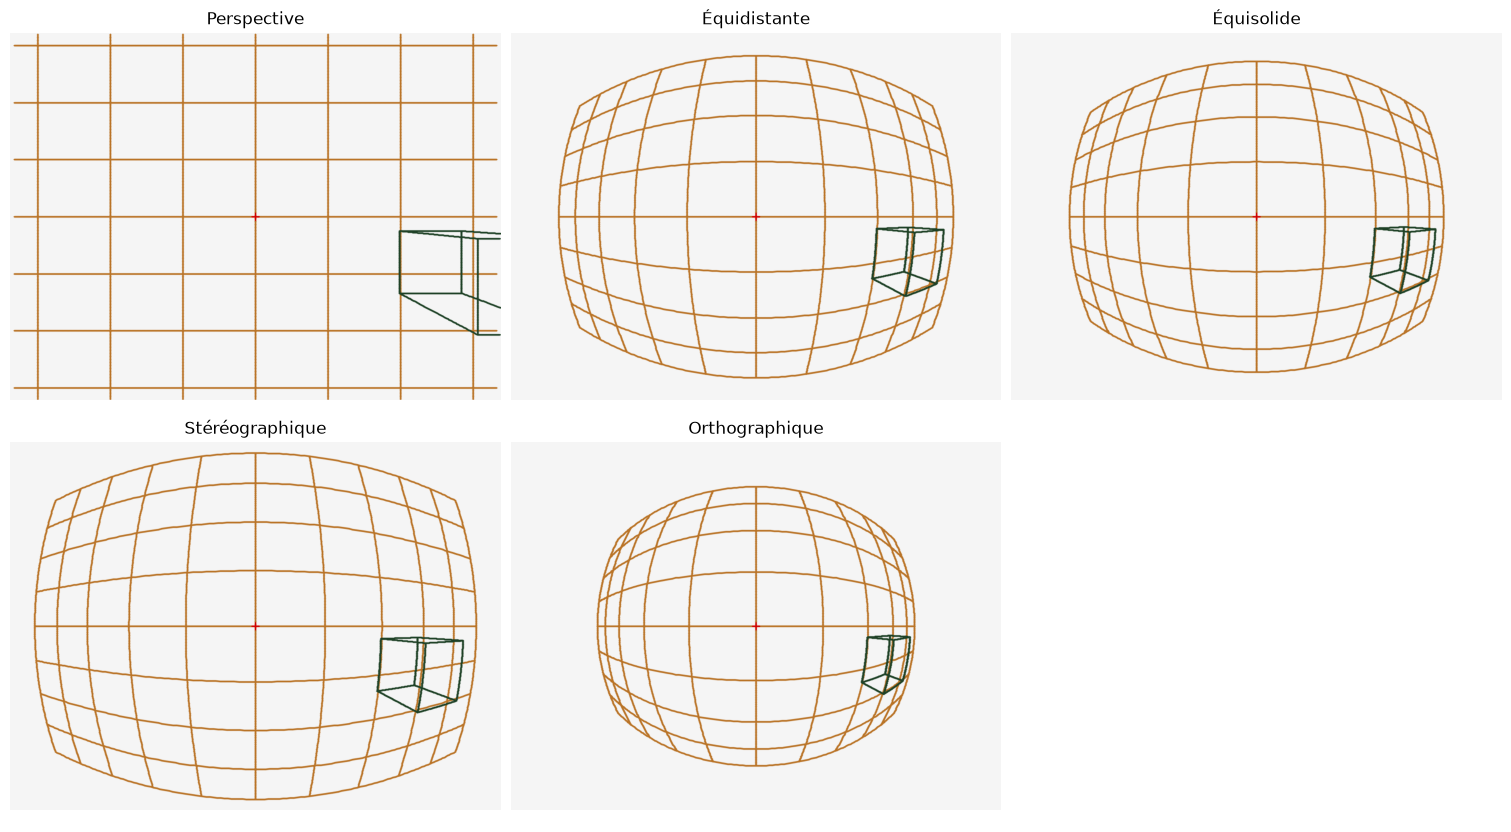

In [23]:
def segment(a, b, n=150):
    t = np.linspace(0, 1, n)[:, None]
    return np.asarray(a)[None,:]*(1-t) + np.asarray(b)[None,:]*t

def make_scene_segments():
    segs=[]
    # Grille sur un mur frontal Z=1.7 ; grandes directions excentrées.
    for x in np.linspace(-3.5, 3.5, 11):
        segs.append(segment([x,-2.2,1.7],[x,2.2,1.7]))
    for y in np.linspace(-2.2, 2.2, 9):
        segs.append(segment([-3.5,y,1.7],[3.5,y,1.7]))
    # Un cube décentré pour provoquer de la courbure et du changement de taille.
    c=np.array([1.35,.35,1.12]); side=.48
    corners=np.array([[i,j,k] for i in [0,1] for j in [0,1] for k in [0,1]],float)
    corners=(corners-.5)*side+c
    for i in range(8):
        for j in range(i+1,8):
            if np.count_nonzero(np.abs(corners[i]-corners[j])>1e-8)==1:
                segs.append(segment(corners[i],corners[j],n=75))
    return segs

SCENE_SEGMENTS = make_scene_segments()
def draw_scene(model, K=K_SIM, theta_max=np.deg2rad(94), D=None):
    w,h=IMAGE_SIZE
    im=np.full((h,w,3),245, dtype=np.uint8)
    for i, xyz in enumerate(SCENE_SEGMENTS):
        uv, good=project_dirs(xyz,K,model,D,theta_max,IMAGE_SIZE)
        # Rupture des polylignes dès que des points deviennent invisibles.
        color=(38,115,185) if i<20 else (38,65,30)  # OpenCV : BGR
        for j in range(len(xyz)-1):
            if good[j] and good[j+1]:
                a,b=np.round(uv[j]).astype(int),np.round(uv[j+1]).astype(int)
                cv2.line(im,tuple(a),tuple(b),color,2,cv2.LINE_AA)
    cv2.drawMarker(im,(int(K[0,2]),int(K[1,2])),(0,0,210),cv2.MARKER_CROSS,14,2)
    return cv2.cvtColor(im,cv2.COLOR_BGR2RGB)

fig, axes=plt.subplots(2,3,figsize=(15,8.2),layout="constrained")
for ax,(name,label) in zip(axes.flat,MODELS.items()):
    ax.imshow(draw_scene(name)); ax.set_title(label); ax.axis("off")
axes.flat[-1].axis("off")
plt.show()

# III - Le modèle fisheye d'OpenCV


Une vraie optique n'est pas nécessairement strictement équidistante. OpenCV propose une **famille de fonctions ajustables**. Soit $D=(k_1,k_2,k_3,k_4)$, 

$$q_D(\theta)=\theta+k_1\theta^3+k_2\theta^5+k_3\theta^7+k_4\theta^9 \qquad \text{ et en particulier } \qquad q_0(\theta)=\theta\quad\text{(modèle équidistant idéal).}$$

La symétrie de révolution conduit à $q(-\theta)=-q(\theta)$ et le développement de Taylor d'une fonction impaire régulière ne contient que des puissances impaires. On a mis $4$ paramètres pour rester général et pratique mais on peut diminuer / augmenter le nombre de $k_i$.
**Limite importante :** toutes les valeurs de $D$ ne sont pas physiquement pertinentes. Il faut notamment que $q_D$ reste monotone sur le champ de vision utilisé, pour que deux directions radiales ne soient pas confondues : $q_D'(\theta)=1+3k_1\theta^2+5k_2\theta^4+7k_3\theta^6+9k_4\theta^8>0$.

Le modèle d'OpenCV n'est pas nécessairement un modèle exact de toute optique fisheye ; pour les objectifs très extrêmes ou non centraux, d'autres modèles existent.


> **Remarque - Pourquoi le polynôme d'OpenCV peut-il modéliser différents fisheyes ?**
>
> Le modèle d'OpenCV part de la projection équidistante $r=f\theta$ et introduit des coefficients $D=(k_1,\ldots,k_4)$ :
>
> $$
> \frac rf=\theta+k_1\theta^3+k_2\theta^5+k_3\theta^7+k_4\theta^9.
> $$
>
> Or, les autres lois de projection admettent des **développements de Taylor** autour de $\theta=0$ (en radians) :
>
> | Modèle | Développement de $r/f$ à l'ordre 9 |
> |---|---|
> | Équidistant | $\theta$ |
> | Équisolide | $\theta-\frac{\theta^3}{24}+\frac{\theta^5}{1920}-\frac{\theta^7}{322560}+\frac{\theta^9}{92897280}$ |
> | Stéréographique | $\theta+\frac{\theta^3}{12}+\frac{\theta^5}{120}+\frac{17\theta^7}{20160}+\frac{31\theta^9}{362880}$ |
> | Orthographique | $\theta-\frac{\theta^3}{6}+\frac{\theta^5}{120}-\frac{\theta^7}{5040}+\frac{\theta^9}{362880}$ |
> | Perspective | $\theta+\frac{\theta^3}{3}+\frac{2\theta^5}{15}+\frac{17\theta^7}{315}+\frac{62\theta^9}{2835}$ |
>
> **Interprétation :** toutes ces projections ont le même comportement au voisinage de l'axe optique ($r\sim f\theta$). Les termes d'ordre supérieur permettent de représenter leurs différences.
>
> Ainsi, en ajustant $D$, le modèle polynomial d'OpenCV peut **approximer différentes lois de projection**, même non équidistantes.
>
> **Attention :** ces développements sont locaux ($\theta\approx0$). En calibration, les coefficients sont estimés à partir des images pour obtenir une bonne approximation sur le champ de vision utilisé.


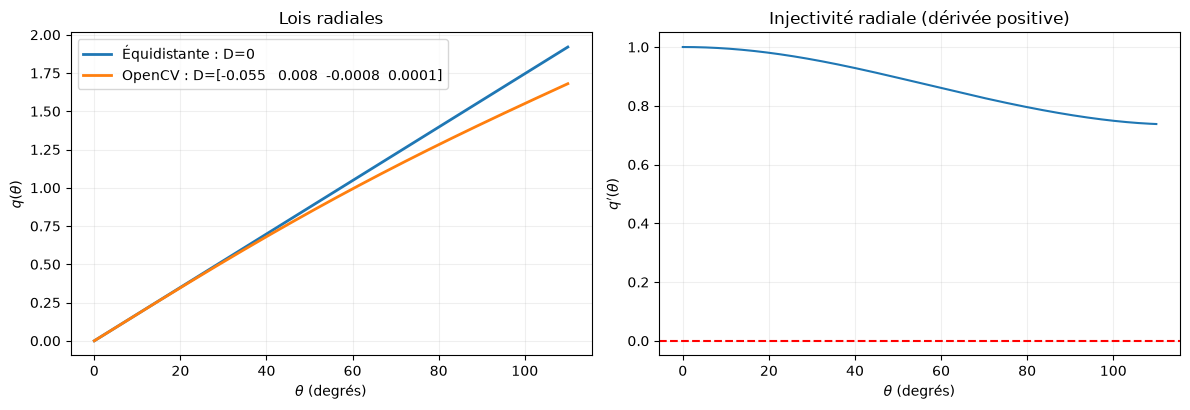

Dérivée minimale sur le domaine étudié : 0.7378938396886431


In [24]:
D_TRUE = np.array([-0.055, 0.0080, -0.0008, 0.00005])  # pour la simulation
D_ZERO = np.zeros(4)
t = np.linspace(0, np.deg2rad(110), 450)
fig, axes=plt.subplots(1,2,figsize=(12,4.2))
axes[0].plot(np.rad2deg(t),q_of_theta(t,"equidistant"),label="Équidistante : D=0",lw=2)
axes[0].plot(np.rad2deg(t),q_of_theta(t,"opencv",D_TRUE),label=f"OpenCV : D={D_TRUE}",lw=2)
axes[0].set(xlabel=r"$\theta$ (degrés)",ylabel=r"$q(\theta)$",title="Lois radiales")
axes[0].legend()
qprime=1+3*D_TRUE[0]*t**2+5*D_TRUE[1]*t**4+7*D_TRUE[2]*t**6+9*D_TRUE[3]*t**8
axes[1].plot(np.rad2deg(t),qprime)
axes[1].axhline(0,color="red",linestyle="--")
axes[1].set(xlabel=r"$\theta$ (degrés)",ylabel=r"$q'(\theta)$",title="Injectivité radiale (dérivée positive)")
plt.tight_layout(); plt.show()
print("Dérivée minimale sur le domaine étudié :",qprime.min())
assert qprime.min()>0

----

## IV - Expérience : influence des vues sur la calibration

**Peut-on calibrer toute l'image si l'on observe le damier uniquement au centre ?** On compare 20 vues centrées et 20 vues réparties sur une grille. La caméra, les orientations, les profondeurs et les réalisations du bruit restent identiques ; seules les positions latérales changent.

On connaît la caméra virtuelle : $K_\star$ et $D_\star=(-0,07;\ 0,012;\ 0;\ 0)$. On ajuste $K,k_1,k_2$ et une pose par vue, en imposant $k_3=k_4=0$. Ce modèle volontairement simple est aussi celui qui génère les données : la comparaison porte sur la couverture du capteur, pas sur le choix du modèle.

Huit nouvelles poses communes servent au **test oracle** : on utilise leurs poses exactes et leurs projections sans bruit. Ainsi, l'erreur de test vient uniquement de la caméra estimée. Aucune pose vraie n'est fournie au solveur pendant la calibration.

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Les constantes ont changé de namespace ET de valeurs entre OpenCV 4 et 5.
F = cv2.fisheye if hasattr(cv2.fisheye, "CALIB_USE_INTRINSIC_GUESS") else cv2
CAL_FLAGS = F.CALIB_USE_INTRINSIC_GUESS | F.CALIB_FIX_SKEW | F.CALIB_RECOMPUTE_EXTRINSIC
CRIT = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 150, 1e-9)

def project(Q, r, t, K, D):
    return cv2.fisheye.projectPoints(Q.reshape(-1, 1, 3), r, t, K, D)[0]

def calibrer(objets, images, size, coefficients=2, centre_fixe=False, focal_ratio=.4):
    w, h = size
    K0 = np.array([[w * focal_ratio, 0., w / 2], [0., w * focal_ratio, h / 2], [0., 0., 1.]])
    flags = CAL_FLAGS | (F.CALIB_FIX_PRINCIPAL_POINT if centre_fixe else 0)
    for k in range(coefficients + 1, 5):
        flags |= getattr(F, f"CALIB_FIX_K{k}")
    # Le format (1, N, coordonnées) fonctionne avec les deux versions.
    obj = [np.ascontiguousarray(Q, dtype=np.float64).reshape(1, -1, 3) for Q in objets]
    img = [np.ascontiguousarray(p, dtype=np.float64).reshape(1, -1, 2) for p in images]
    rms, K, D, r, t = cv2.fisheye.calibrate(obj, img, size, K0, np.zeros((4, 1)), flags=flags, criteria=CRIT)
    return {"rms": rms, "K": K, "D": D, "poses": list(zip(r, t))}

W, H = IMAGE_SIZE
K_TRUE = np.array([[415., 0., W / 2 + 3], [0., 410., H / 2 - 4], [0., 0., 1.]])
D_CAL_TRUE = np.array([-.07, .012, 0., 0.])
PATTERN_SIZE, SQUARE_M = (9, 6), .045
board_xyz = np.zeros((54, 1, 3), np.float64)
board_xyz[:, 0, :2] = (np.mgrid[:9, :6].T.reshape(-1, 2) - [4, 2.5]) * SQUARE_M
print("OpenCV", cv2.__version__, "- calibration avec k1 et k2 libres")

OpenCV 5.0.0 - calibration avec k1 et k2 libres


### 1. Construire les deux acquisitions

Les centres visés sont exprimés en pixels. On les déprojette pour placer le centre du damier dans la bonne direction 3D. Le bruit vaut 0,15 px par coordonnée ; les coins restent à l'intérieur du capteur. Les damiers sont plans dans l'espace : leurs courbes apparentes viennent de la projection fisheye.

In [26]:
def generer_vues(centres, rotations, profondeurs, bruit):
    vues = []
    for centre, r, z, eps in zip(centres, rotations, profondeurs, bruit):
        xy = cv2.fisheye.undistortPoints(np.array(centre, float).reshape(1, 1, 2), K_TRUE, D_CAL_TRUE)[0, 0]
        t = np.r_[z * xy, z]
        exact = project(board_xyz, r, t, K_TRUE, D_CAL_TRUE)
        assert ((exact >= 0) & (exact < [W, H])).all(), "Un damier sort du capteur"
        vues.append({"pixels": exact + eps, "exact": exact, "r": r, "t": t})
    return vues

rng = np.random.default_rng(2026)
N, SIGMA = 20, .15
rotations = rng.uniform([-.5, -.5, -.35], [.5, .5, .35], (N, 3))
profondeurs = rng.uniform(.9, 1.25, N)
bruit = rng.normal(0, SIGMA, (N, 54, 1, 2))
centres_A = K_TRUE[:2, 2] + np.column_stack([rng.uniform(-45, 45, N), rng.uniform(-35, 35, N)])
centres_B = np.array([(x * W, y * H) for y in (.17, .39, .61, .83) for x in (.15, .325, .5, .675, .85)])
rng.shuffle(centres_B)
lots = {name: generer_vues(c, rotations, profondeurs, bruit) for name, c in [("Centre", centres_A), ("Réparti", centres_B)]}
centres_test = np.array([(.15, .2), (.85, .2), (.15, .8), (.85, .8), (.5, .17), (.5, .83), (.17, .5), (.83, .5)]) * [W, H]
test = generer_vues(centres_test, rng.uniform([-.4, -.4, -.3], [.4, .4, .3], (8, 3)), rng.uniform(.9, 1.2, 8), np.zeros((8, 54, 1, 2)))
print("20 vues par lot ; 8 poses de test sans bruit, absentes de la calibration.")

20 vues par lot ; 8 poses de test sans bruit, absentes de la calibration.


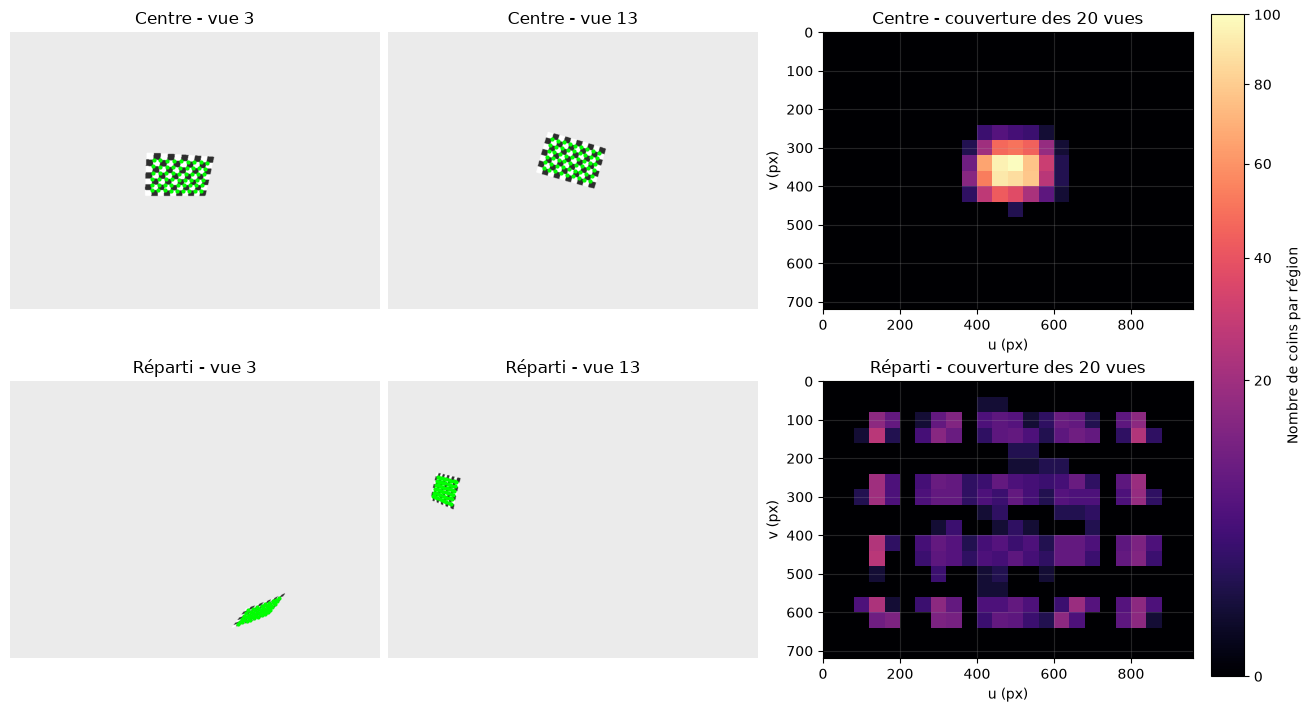

In [27]:
from matplotlib.colors import PowerNorm

def dessiner_damier(vue):
    image = np.full((H, W, 3), 235, np.uint8)
    a = np.linspace(0, 1, 16, endpoint=False)
    for y in range(7):
        for x in range(10):
            sommets = (np.array([[x, y], [x + 1, y], [x + 1, y + 1], [x, y + 1]]) - [5, 3.5]) * SQUARE_M
            # Échantillonner les arêtes pour dessiner leur courbure, pas seulement les sommets.
            bord = np.concatenate([(1 - a[:, None]) * p + a[:, None] * q for p, q in zip(sommets, np.roll(sommets, -1, axis=0))])
            Q = np.column_stack([bord, np.zeros(len(bord))])
            poly = project(Q, vue["r"], vue["t"], K_TRUE, D_CAL_TRUE).round().astype(np.int32)
            cv2.fillPoly(image, [poly], (45, 45, 45) if (x + y) % 2 else (255, 255, 255), cv2.LINE_AA)
    return image

histos = [np.histogram2d(*np.concatenate([v["pixels"] for v in vues]).reshape(-1, 2).T, bins=(24, 18), range=[[0, W], [0, H]])[0] for vues in lots.values()]
fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout="constrained")
for row, (name, vues) in enumerate(lots.items()):
    for ax, j in zip(axes[row, :2], [2, 12]):
        ax.imshow(dessiner_damier(vues[j]))
        ax.scatter(*vues[j]["pixels"].reshape(-1, 2).T, s=4, c="lime")
        ax.set_title(f"{name} - vue {j + 1}")
        ax.axis("off")
    im = axes[row, 2].imshow(histos[row].T, extent=[0, W, H, 0], cmap="magma", norm=PowerNorm(.5, vmin=0, vmax=max(h.max() for h in histos)))
    axes[row, 2].set(title=f"{name} - couverture des 20 vues", xlabel="u (px)", ylabel="v (px)")
fig.colorbar(im, ax=axes[:, 2], label="Nombre de coins par région")
plt.show()

### 2. Calibrer, puis mesurer l'erreur ailleurs

On minimise la somme des écarts au carré entre coins observés et projetés. Les intrinsèques sont communs aux vues ; chaque damier a sa pose. L'initialisation est approximative, sans fournir les vrais paramètres.

La métrique est la **RMSE 2D** : $\sqrt{\frac{1}{N}\sum_i\|p_i-\hat p_i\|^2}$. L'ajustement porte sur des mesures bruitées et des poses estimées ; l'oracle utilise des points exacts et des poses imposées. Son erreur n'a donc pas de plancher de bruit. On affiche aussi les écarts de focale et de point principal : une petite erreur sur $K$ ne suffit pas à valider $D$.

In [28]:
def erreurs_oracle(fit, vues):
    angles, erreurs = [], []
    for v in vues:
        pred = project(board_xyz, v["r"], v["t"], fit["K"], fit["D"])
        erreurs.extend(np.linalg.norm((pred - v["exact"]).reshape(-1, 2), axis=1))
        xyz = board_xyz[:, 0] @ cv2.Rodrigues(v["r"])[0].T + v["t"]
        angles.extend(np.degrees(np.arctan2(np.linalg.norm(xyz[:, :2], axis=1), xyz[:, 2])))
    return np.array(angles), np.array(erreurs)

fits = {name: calibrer([board_xyz] * N, [v["pixels"] for v in vues], IMAGE_SIZE) for name, vues in lots.items()}
print(f"{'Lot':10} {'Ajustement (px)':>16} {'Oracle (px)':>13} {'Focale max (%)':>16} {'Point principal (px)':>22}")
for name, fit in fits.items():
    err = erreurs_oracle(fit, test)[1]
    df = 100 * np.max(np.abs(fit["K"].diagonal()[:2] / K_TRUE.diagonal()[:2] - 1))
    dc = np.linalg.norm(fit["K"][:2, 2] - K_TRUE[:2, 2])
    print(f"{name:10} {fit['rms']:16.3f} {np.sqrt(np.mean(err**2)):13.3f} {df:16.2f} {dc:22.2f}")
    print("  k1, k2 estimés :", np.round(fit["D"].ravel()[:2], 5))

# Contrôle : la même procédure doit retrouver la projection vraie sans bruit.
sans_bruit = calibrer([board_xyz] * N, [v["exact"] for v in lots["Réparti"]], IMAGE_SIZE)
assert erreurs_oracle(sans_bruit, test)[1].max() < 1e-3
print("Contrôle sans bruit : erreur oracle maximale < 0,001 px.")

Lot         Ajustement (px)   Oracle (px)   Focale max (%)   Point principal (px)
Centre                0.209        17.657             0.18                   1.77
  k1, k2 estimés : [-0.0641 -0.0452]
Réparti               0.209         0.888             0.11                   0.82
  k1, k2 estimés : [-0.0734  0.016 ]
Contrôle sans bruit : erreur oracle maximale < 0,001 px.


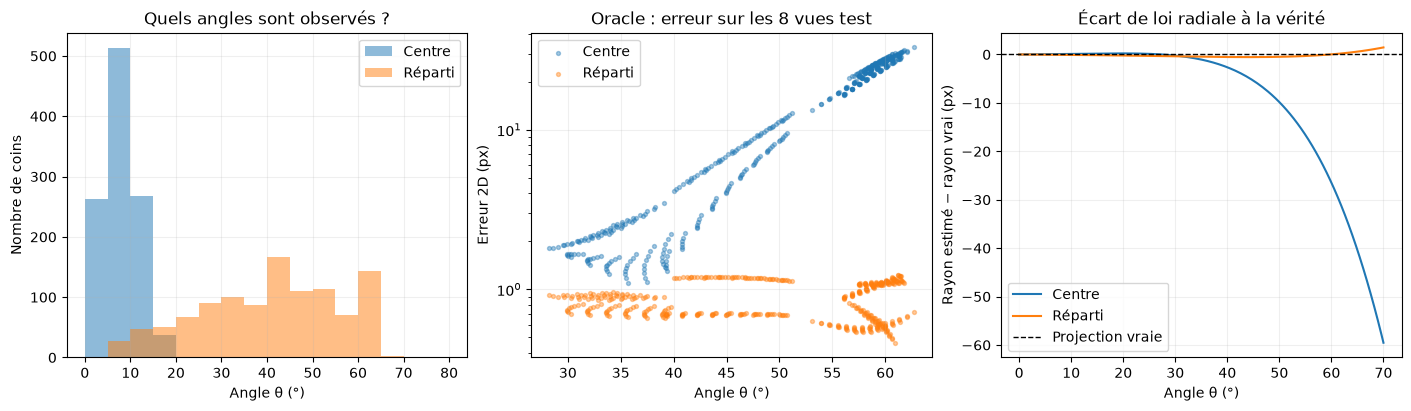

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
theta = np.deg2rad(np.linspace(0, 70, 200))
rays = np.column_stack([np.sin(theta), np.zeros_like(theta), np.cos(theta)])
radial_true = project(rays, np.zeros(3), np.zeros(3), K_TRUE, D_CAL_TRUE)[:, 0, 0] - K_TRUE[0, 2]
for name, fit in fits.items():
    angles_train, _ = erreurs_oracle(fit, lots[name])
    axes[0].hist(angles_train, bins=np.arange(0, 81, 5), alpha=.5, label=name)
    angles, err = erreurs_oracle(fit, test)
    axes[1].scatter(angles, err, s=8, alpha=.4, label=name)
    radial = project(rays, np.zeros(3), np.zeros(3), fit["K"], fit["D"])[:, 0, 0] - fit["K"][0, 2]
    axes[2].plot(np.degrees(theta), radial - radial_true, label=name)
axes[0].set(title="Quels angles sont observés ?", xlabel="Angle θ (°)", ylabel="Nombre de coins")
axes[1].set(title="Oracle : erreur sur les 8 vues test", xlabel="Angle θ (°)", ylabel="Erreur 2D (px)", yscale="log")
axes[2].axhline(0, color="black", lw=1, linestyle="--", label="Projection vraie")
axes[2].set(title="Écart de loi radiale à la vérité", xlabel="Angle θ (°)", ylabel="Rayon estimé − rayon vrai (px)")
for ax in axes:
    ax.legend()
plt.show()

### Lecture des résultats

L'histogramme indique la plage angulaire réellement contrainte par les observations. L'oracle mesure les erreurs sur de nouveaux damiers. La dernière courbe montre l'écart de loi radiale le long de l'axe horizontal, relativement à chaque point principal : elle isole l'effet focale/distorsion, sans mesurer le décalage du point principal.

Avec les paramètres proposés, les deux ajustements donnent **0,21 px**, mais l'oracle passe d'environ **17,7 px (Centre) à 0,89 px (Réparti)**. La différence vient donc de ce que les calibrations prédisent hors des observations, pas de leur capacité à reproduire leurs propres points.

Au centre, les termes en $\theta^3$ et $\theta^5$ sont petits : des coefficients différents peuvent donner presque les mêmes pixels. Une faible RMSE d'ajustement peut donc coexister avec une mauvaise extrapolation. Répartir les observations améliore cette contrainte ; il faut également varier les inclinaisons et les distances.


## 15 - Une erreur de calibration, ça change quoi en 3D ?
Un pixel $(u,v)$ permet de retrouver une **direction 3D**, à condition de connaître les paramètres de projection $K,D$.

Nous simulons un rayon connu, le projetons en pixel, puis reconstruisons sa direction :
- **Avec les vrais paramètres $D$** : on retrouve le rayon initial (erreur angulaire presque nulle).
- **En supposant $D=0$** : la direction reconstruite peut être erronée, notamment aux grands angles.

L'inversion de la loi radiale $s=q_D(\theta)$ est effectuée numériquement par la méthode de Newton.

**Conclusion :** une mauvaise calibration ne déplace pas seulement les pixels lors de la reprojection : elle fausse également les directions 3D reconstruites. Cette erreur peut ensuite affecter la triangulation stéréo et l'estimation de profondeur. Une caméra monoculaire fournit une direction, mais pas la distance de l'objet.

> ### Partie technique pour le code si dessous
> Pour un modèle central, un pixel donne un **rayon** :
> $$p=(u,v)\quad\longmapsto\quad d(p;K,D)\in\mathbb S^2.$$
> 
> La direction ne détermine **pas** la distance : tous les points $X_c(\lambda)=\lambda d$, pour $\lambda>0$, ont la même direction dans la caméra centrale.
> 
> Pour récupérer $d$ depuis le pixel avec une distorsion radiale, il faut résoudre :
> 
> $$s=\sqrt{\left(\frac{u-c_x}{f_x}\right)^2+\left(\frac{v-c_y}{f_y}\right)^2}
> =q_D(\theta).$$
> 
> On inverse numériquement $q_D$ (si elle est monotone sur le champ étudié), puis :
> 
> $$d=(\sin\theta\cos\varphi,\ \sin\theta\sin\varphi,\ \cos\theta),\quad \varphi=\operatorname{atan2}\left(\frac{v-c_y}{f_y},\frac{u-c_x}{f_x}\right).$$



In [30]:
def invert_opencv_radius(s, D, theta_max=np.deg2rad(110), iterations=20):
    """Inverse vectorisé de q_D(theta), valide seulement si q_D croît sur le domaine."""
    s=np.asarray(s,float)
    k1,k2,k3,k4=np.asarray(D,float).ravel()
    theta=np.clip(s,0,theta_max)
    for _ in range(iterations):
        poly=theta*(1+k1*theta**2+k2*theta**4+k3*theta**6+k4*theta**8)
        deriv=1+3*k1*theta**2+5*k2*theta**4+7*k3*theta**6+9*k4*theta**8
        theta=np.clip(theta-(poly-s)/np.maximum(deriv,1e-8),0,theta_max)
    return theta

def pixel_to_ray_opencv(pixel,K,D,theta_max=np.deg2rad(110)):
    p=np.asarray(pixel,float)
    xn=(p[...,0]-K[0,2])/K[0,0]
    yn=(p[...,1]-K[1,2])/K[1,1]
    s=np.hypot(xn,yn)
    phi=np.arctan2(yn,xn)
    theta=invert_opencv_radius(s,D,theta_max)
    rays=np.stack((np.sin(theta)*np.cos(phi),np.sin(theta)*np.sin(phi),np.cos(theta)),axis=-1)
    valid=np.isfinite(rays).all(axis=-1)&(s<=q_of_theta(theta_max,"opencv",D)+1e-8)
    return rays,valid

ray=np.array([np.sin(np.deg2rad(65)),0,np.cos(np.deg2rad(65))])
pixel,visible=project_dirs(ray,K_TRUE,"opencv",D_CAL_TRUE,theta_max=np.deg2rad(100),image_size=IMAGE_SIZE)
assert bool(visible), "Le rayon choisi doit tomber dans le capteur"
recovered,_=pixel_to_ray_opencv(pixel,K_TRUE,D_CAL_TRUE)
wrong,_=pixel_to_ray_opencv(pixel,K_TRUE,np.zeros((4,1)))
ang_err=lambda a,b: np.rad2deg(np.arccos(np.clip(np.dot(a,b),-1,1)))
print("Rayon vrai :",ray)
print("Pixel observé :",pixel)
print("Erreur angulaire avec D vrai :",ang_err(ray,recovered),"degré")
print("Erreur angulaire en supposant D=0 :",ang_err(ray,wrong),"degré")
assert ang_err(ray,recovered)<1e-5

Rayon vrai : [0.9063 0.     0.4226]
Pixel observé : [920.7457 356.    ]
Erreur angulaire avec D vrai : 0.0 degré
Erreur angulaire en supposant D=0 : 4.563904039988174 degré


## 16 - Pourquoi deux caméras permettent-elles d'estimer une profondeur ?

**Monoculaire calibré :** un point image donne une demi-droite $C_1+\lambda_1d_1$ ; il reste une inconnue de distance $\lambda_1$.

**Stéréo calibrée :** le même point observé par une seconde caméra définit $C_2+\lambda_2d_2$. En connaissant la transformation relative $(R_{12},t_{12})$, on peut résoudre les deux distances en rapprochant les rayons :

$$\min_{\lambda_1,\lambda_2\ge0}\left\|(C_1+\lambda_1d_1)-(C_2+\lambda_2d_2)\right\|^2.$$

Dans le cas perspective **rectifié** classique, $Z=fb/\delta$ (focale $f$, base $b$, disparité $\delta$) : ce n'est **pas** une formule à appliquer directement aux pixels fisheye bruts !

Pour une carte de profondeur **dense**, on répète le problème pour beaucoup de pixels **après avoir trouvé les correspondances inter-caméras**. La calibration est nécessaire à la géométrie ; elle ne résout pas à elle seule les correspondances et les occultations.

In [31]:
# Mini-triangulation de rayons, sans hypothèse de projection perspective
C1=np.array([0.,0.,0.]); C2=np.array([.20,0.,0.]) # base de 20 cm
point_3d=np.array([.45,-.05,2.00])  # point réel en mètres
d1=(point_3d-C1)/np.linalg.norm(point_3d-C1)
d2=(point_3d-C2)/np.linalg.norm(point_3d-C2)
# C1+lambda1*d1 = C2+lambda2*d2 -> [d1, -d2] @ lambda = C2-C1
lambdas,*_=np.linalg.lstsq(np.column_stack([d1,-d2]),C2-C1,rcond=None)
X1=C1+lambdas[0]*d1
X2=C2+lambdas[1]*d2
estimated=.5*(X1+X2)
print("Vérité terrain :",point_3d,"m")
print("Triangulation : ",estimated,"m")
print("Écart (m) :",np.linalg.norm(estimated-point_3d))
assert np.allclose(estimated,point_3d,atol=1e-10)

Vérité terrain : [ 0.45 -0.05  2.  ] m
Triangulation :  [ 0.45 -0.05  2.  ] m
Écart (m) : 9.466736793065328e-15


# V - Calibration réelle : mesurer ce qui fonctionne

On utilise les **26 photographies fisheye** du dépôt [4rtur1t0/fisheye_calibration](https://github.com/4rtur1t0/fisheye_calibration), dans une [version figée](https://github.com/4rtur1t0/fisheye_calibration/tree/558e1c0885582a14561da49188ace2b1473408aa). La configuration indique **8 × 6 coins intérieurs** et un pas de 25 sans unité explicite. On choisit donc la case comme unité : les translations ne seront pas en mètres.

Le protocole : télécharger les photos → détecter les coins → réserver une vue sur cinq au test → calibrer → comparer pixels observés et prédits. Les images sont réduites à **1 000 px de large** ; toutes les erreurs et focales ci-dessous correspondent à cette résolution. Les données téléchargées (~78 Mo) sont réutilisées aux exécutions suivantes.

In [32]:
from urllib.request import urlretrieve

COMMIT = "558e1c0885582a14561da49188ace2b1473408aa"
BASE_URL = f"https://raw.githubusercontent.com/4rtur1t0/fisheye_calibration/{COMMIT}"
REAL_DIR = Path("data/fisheye_example")
REAL_DIR.mkdir(parents=True, exist_ok=True)
names = "V3382452 V3402456 V3422460 V3442464 V3462468 V3482472 V3502476 V3512478 V3532482 V3552486 V3572490 V3592494 V3622500 V3652506 V3662508 V3682512 V3702516 V3722520 V3742524 V3752526 V3762528 V3772530 V3782532 V3792534 V3802536 V3812538".split()
for name in names:
    path = REAL_DIR / f"{name}.JPG"
    if not path.exists():
        temporary = path.with_suffix(".part")
        urlretrieve(f"{BASE_URL}/calib_images/{path.name}", temporary)
        temporary.replace(path)
print(f"{len(names)} photographies disponibles dans {REAL_DIR}")

26 photographies disponibles dans data\fisheye_example


### 1. Détections et couverture

Les coins sont localisés avec `findChessboardCornersSB`. Une photo sans damier complet est signalée et exclue avant la séparation calibration/test. La carte montre où les paramètres seront contraints ; les régions sans coins ne sont pas validées par cette expérience.

Damier non détecté : V3512478
Damier non détecté : V3772530
24/26 détections ; 19 vues de calibration, 5 de test ; résolution (1000, 997)


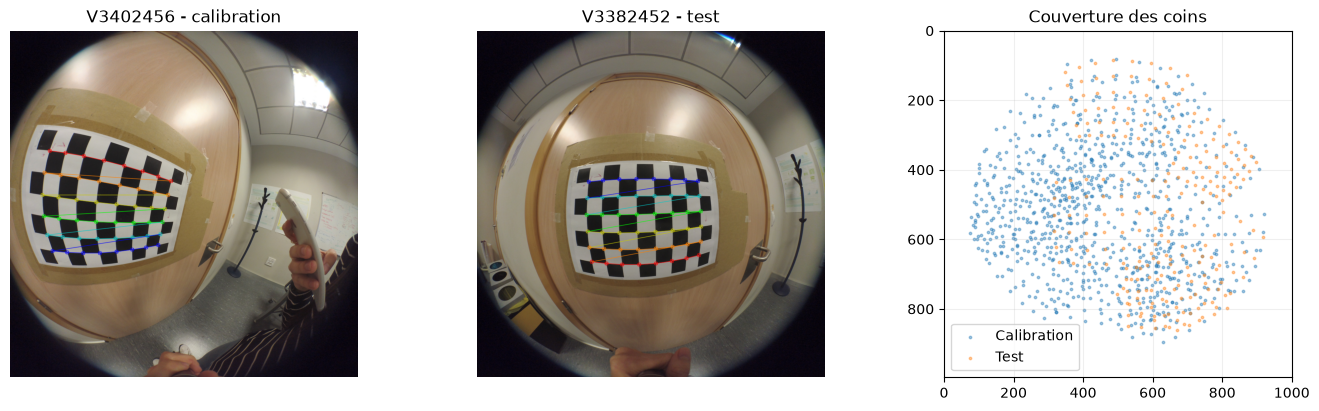

In [33]:
PATTERN_REAL = (8, 6)
obj_real = np.zeros((48, 1, 3), np.float64)
obj_real[:, 0, :2] = np.mgrid[:8, :6].T.reshape(-1, 2)
photos, corners_real, kept_names = [], [], []
for name in names:
    image = cv2.imread(str(REAL_DIR / f"{name}.JPG"), cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)
    if image is None:
        raise ValueError(f"Image illisible : {name}")
    h, w = image.shape[:2]
    image = cv2.resize(image, (1000, round(h * 1000 / w)), interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    found, corners = cv2.findChessboardCornersSB(gray, PATTERN_REAL, flags=cv2.CALIB_CB_NORMALIZE_IMAGE)
    if found:
        photos.append(image)
        corners_real.append(corners.astype(np.float64).reshape(-1, 1, 2))
        kept_names.append(name)
    else:
        print("Damier non détecté :", name)
assert len(photos) >= 10, "Pas assez de vues détectées pour séparer calibration et test."
size_real = photos[0].shape[1::-1]
assert all(image.shape[1::-1] == size_real for image in photos)
test_ids = list(range(0, len(photos), 5))
train_ids = [i for i in range(len(photos)) if i not in test_ids]
print(f"{len(photos)}/{len(names)} détections ; {len(train_ids)} vues de calibration, {len(test_ids)} de test ; résolution {size_real}")
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for ax, i in zip(axes[:2], [train_ids[0], test_ids[0]]):
    overlay = photos[i].copy()
    cv2.drawChessboardCorners(overlay, PATTERN_REAL, corners_real[i].astype(np.float32), True)
    ax.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    ax.set_title(kept_names[i] + (" - test" if i in test_ids else " - calibration"))
    ax.axis("off")
for ids, label in [(train_ids, "Calibration"), (test_ids, "Test")]:
    points = np.concatenate([corners_real[i] for i in ids]).reshape(-1, 2)
    axes[2].scatter(*points.T, s=3, alpha=.4, label=label)
axes[2].set(xlim=(0, size_real[0]), ylim=(size_real[1], 0), title="Couverture des coins", aspect="equal")
axes[2].legend()
plt.show()

### 2. Ajuster la caméra et contrôler l'optimisation

Sur ce petit jeu, on suit les hypothèses du dépôt : point principal au centre, $k_4=0$, cisaillement nul. On estime donc $f_x,f_y,k_1,k_2,k_3$ et les poses. Ces choix limitent les inconnues, mais peuvent introduire un biais si l'objectif n'est pas bien centré.

OpenCV fournit une première calibration. **On vérifie ses résidus** : une pose peut être mal estimée même si les intrinsèques sont proches d'une solution utile. On initialise alors les poses avec `solvePnP`, puis on raffine **ensemble** les cinq paramètres de caméra et les poses avec `least_squares`, sur les seules vues de calibration. L'objectif reste la somme des erreurs en pixels fisheye ; aucune vue n'est retirée pour améliorer le score.

La matrice `jac_sparsity` indique seulement au solveur quelles variables influencent chaque résidu, pour accélérer le calcul. Elle ne change pas le problème.

**Résumé** : Problème non-linéaire à optimiser donc on se rapproche de la solution en plusieurs étapes :  
**Étape 1** - Calibration OpenCV : Première estimation de \(K,D\) et des poses.  
**Étape 2** - solvePnP : Nouvelle estimation de la pose de chaque damier, en gardant \(K,D\) fixes.  
**Étape 3** - least_squares par vue : Affinement de chaque pose en minimisant l'erreur de projection fisheye.  
**Étape 4** - least_squares global : Optimisation simultanée des 5 paramètres de caméra et de toutes les poses.  [Raffinement]  

On a $K,D$ (donc $f_x$, $f_y$ et $k_1$, $k_2$, $k_3$) qui sont communs à toutes les images (on en a une vingtaine $N \approx 20$ ) mais pour chaque image on a $R_i$ et $t_i$ à estimer.  
Ca fait un total de $5 + N*(3+3) \approx 125$ inconnues.

In [34]:
from scipy.optimize import least_squares
from scipy.sparse import lil_matrix

def estimer_pose(pixels, K, D):
    normalises = cv2.fisheye.undistortPoints(pixels, K, D)
    ok, r, t = cv2.solvePnP(obj_real, normalises, np.eye(3), None)
    assert ok, "Initialisation de pose impossible"
    fit = least_squares(lambda p: (project(obj_real, p[:3], p[3:], K, D) - pixels).ravel(), np.r_[r.ravel(), t.ravel()], max_nfev=300)
    assert fit.success, fit.message
    xyz = obj_real[:, 0] @ cv2.Rodrigues(fit.x[:3])[0].T + fit.x[3:]
    assert (xyz[:, 2] > 0).all(), "Pose derrière la caméra"
    return fit.x

initial = calibrer([obj_real] * len(train_ids), [corners_real[i] for i in train_ids], size_real, coefficients=3, centre_fixe=True, focal_ratio=1 / np.pi)
poses0 = [estimer_pose(corners_real[i], initial["K"], initial["D"]) for i in train_ids]
x0 = np.r_[initial["K"][0, 0], initial["K"][1, 1], initial["D"].ravel()[:3], np.array(poses0).ravel()]

def unpack(x):
    w, h = size_real
    K = np.array([[x[0], 0., w / 2], [0., x[1], h / 2], [0., 0., 1.]])
    return K, np.r_[x[2:5], 0.], x[5:].reshape(-1, 6)

def residuals_calibration(x):
    K, D, poses = unpack(x)
    return np.concatenate([(project(obj_real, p[:3], p[3:], K, D) - corners_real[i]).ravel() for p, i in zip(poses, train_ids)])

block = 2 * len(obj_real)
sparsity = lil_matrix((block * len(train_ids), len(x0)), dtype=int)
for j in range(len(train_ids)):
    sparsity[j * block:(j + 1) * block, :5] = 1
    sparsity[j * block:(j + 1) * block, 5 + 6 * j:11 + 6 * j] = 1
solution = least_squares(residuals_calibration, x0, jac_sparsity=sparsity.tocsr(), x_scale="jac", max_nfev=300)
assert solution.success, solution.message
K_real, D_real, poses_train = unpack(solution.x)
assert K_real[0, 0] > 0 and K_real[1, 1] > 0
print(f"RMSE brute OpenCV : {initial['rms']:.3f} px")
print(f"RMSE après raffinement conjoint : {np.sqrt(np.mean(solution.fun**2) * 2):.3f} px")
print("K =\n", np.round(K_real, 3))
print("D =", np.round(D_real, 6))

RMSE brute OpenCV : 70.145 px
RMSE après raffinement conjoint : 0.584 px
K =
 [[220.754   0.    500.   ]
 [  0.    220.759 498.5  ]
 [  0.      0.      1.   ]]
D = [ 0.1439 -0.0151 -0.0001  0.    ]


### 3. Quel niveau d'erreur sur les vues réservées ?

Pour chaque vue test, $K,D$ restent **figés**. On estime uniquement les six paramètres de pose. Ce n'est pas un oracle : une partie des erreurs intrinsèques peut être absorbée par la pose. C'est un test de cohérence sur des images absentes de l'ajustement de la caméra.

On regarde trois diagnostics complémentaires : RMSE par photo, proportion de coins sous une erreur donnée, puis erreur selon la position dans l'image. **1 px est un repère de lecture**, pas un seuil de sécurité robotique. Le percentile 95 indique l'erreur sous laquelle se trouvent 95 % des coins.

Lot             RMSE (px)    Médiane        P95        Max   Coins < 1 px
Calibration         0.584      0.488      1.003      1.574          94.7%
Test                0.529      0.440      0.926      1.409          96.7%


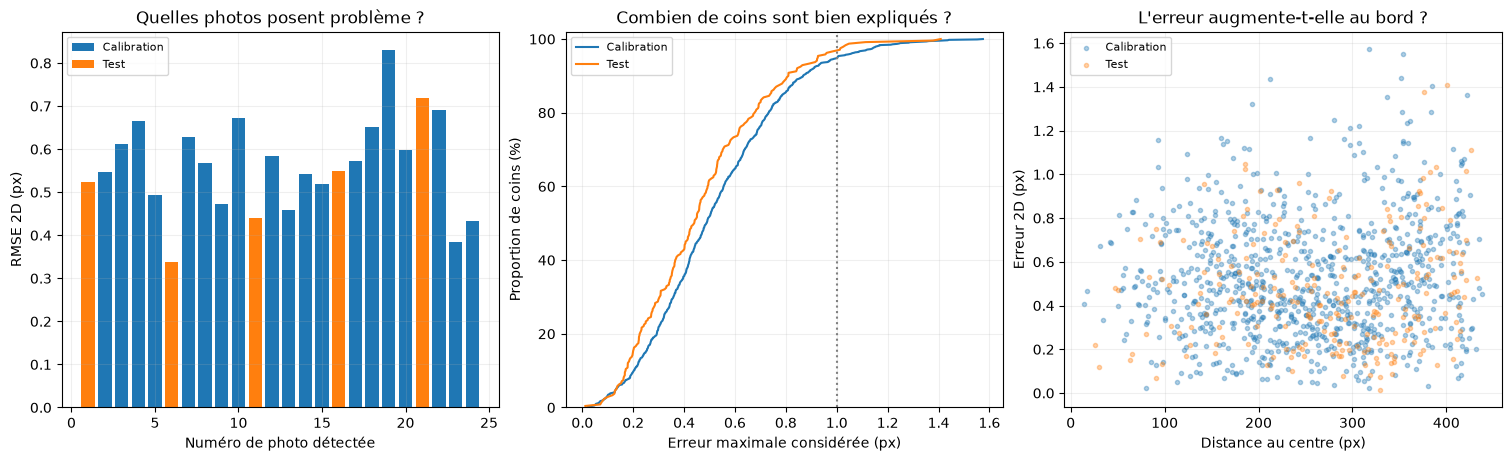

Loi radiale croissante jusqu'à 77.9° (zone observée).


In [35]:
predictions, residuals = {}, {}
for i, pose in zip(train_ids, poses_train):
    predictions[i] = project(obj_real, pose[:3], pose[3:], K_real, D_real)
for i in test_ids:
    pose = estimer_pose(corners_real[i], K_real, D_real)
    predictions[i] = project(obj_real, pose[:3], pose[3:], K_real, D_real)
for i in range(len(photos)):
    residuals[i] = (predictions[i] - corners_real[i]).reshape(-1, 2)
errors = {i: np.linalg.norm(r, axis=1) for i, r in residuals.items()}
rmse_view = np.array([np.sqrt(np.mean(errors[i]**2)) for i in range(len(photos))])

print(f"{'Lot':12} {'RMSE (px)':>12} {'Médiane':>10} {'P95':>10} {'Max':>10} {'Coins < 1 px':>14}")
for label, ids in [("Calibration", train_ids), ("Test", test_ids)]:
    e = np.concatenate([errors[i] for i in ids])
    print(f"{label:12} {np.sqrt(np.mean(e**2)):12.3f} {np.median(e):10.3f} {np.percentile(e, 95):10.3f} {e.max():10.3f} {100 * np.mean(e < 1):13.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout="constrained")
for label, ids, color in [("Calibration", train_ids, "tab:blue"), ("Test", test_ids, "tab:orange")]:
    axes[0].bar(np.array(ids) + 1, rmse_view[ids], color=color, label=label)
    e = np.sort(np.concatenate([errors[i] for i in ids]))
    axes[1].plot(e, 100 * np.arange(1, len(e) + 1) / len(e), label=label, color=color)
    uv = np.concatenate([corners_real[i] for i in ids]).reshape(-1, 2)
    radius = np.linalg.norm(uv - K_real[:2, 2], axis=1)
    axes[2].scatter(radius, np.concatenate([errors[i] for i in ids]), s=9, alpha=.35, label=label, color=color)
axes[0].set(title="Quelles photos posent problème ?", xlabel="Numéro de photo détectée", ylabel="RMSE 2D (px)")
axes[1].axvline(1, color="gray", linestyle=":")
axes[1].set(title="Combien de coins sont bien expliqués ?", xlabel="Erreur maximale considérée (px)", ylabel="Proportion de coins (%)", ylim=(0, 102))
axes[2].set(title="L'erreur augmente-t-elle au bord ?", xlabel="Distance au centre (px)", ylabel="Erreur 2D (px)")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

# Vérification du modèle radial sur les directions effectivement observées.
points = np.concatenate(corners_real)
norm = cv2.fisheye.undistortPoints(points, K_real, D_real).reshape(-1, 2)
theta_max = np.arctan(np.linalg.norm(norm, axis=1)).max()
theta = np.linspace(0, theta_max, 300)
derivative = 1 + sum((2 * j + 3) * k * theta**(2 * j + 2) for j, k in enumerate(D_real))
assert derivative.min() > 0, "Projection radiale non monotone dans la zone observée"
print(f"Loi radiale croissante jusqu'à {np.degrees(theta_max):.1f}° (zone observée).")

### 4. Voir les écarts sur les photos

On affiche la meilleure et la moins bonne **vue test**, selon leur RMSE. À gauche : un recadrage du damier, avec coins détectés et reprojetés à leur vraie position. À droite : les mêmes écarts, **amplifiés ×20** pour rendre leur direction visible. Les flèches vont de l'observation vers la prédiction ; elles ne représentent pas des déplacements physiques.

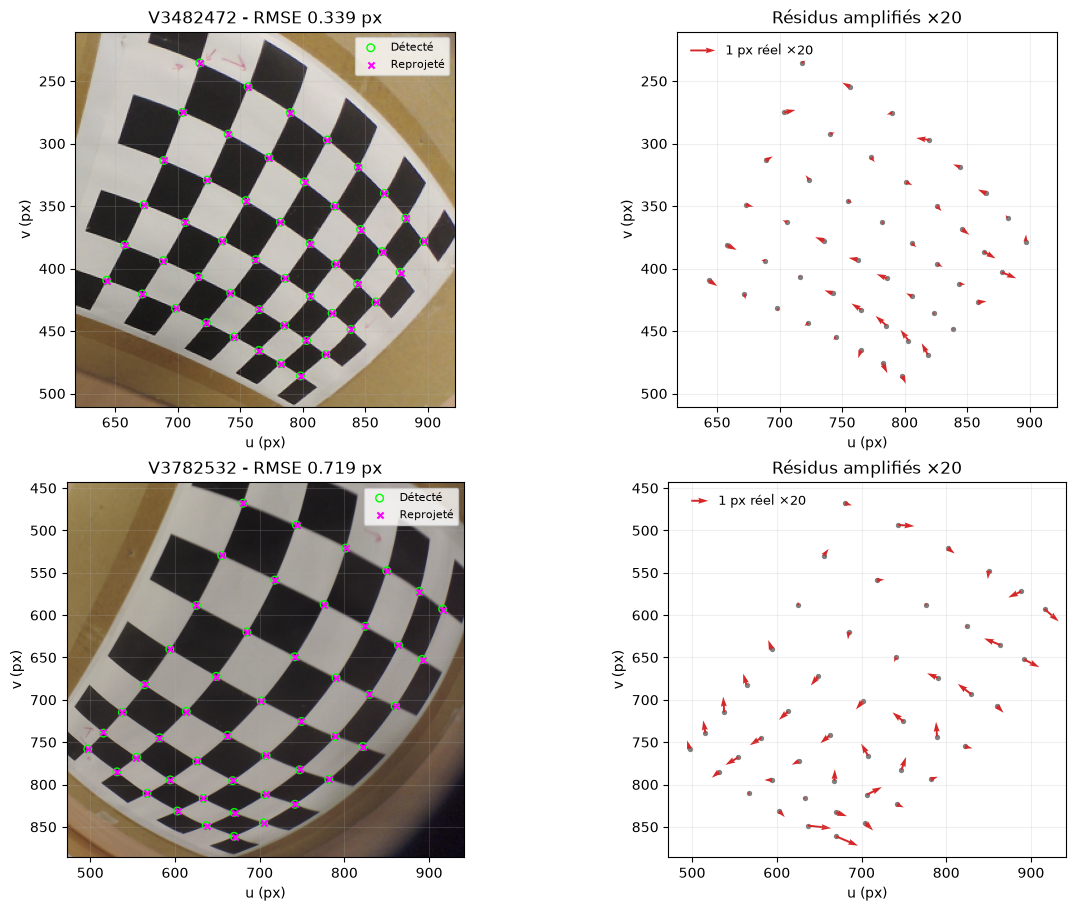

Meilleure vue test : V3482472 ; moins bonne : V3782532.


In [36]:
best = min(test_ids, key=lambda i: rmse_view[i])
worst = max(test_ids, key=lambda i: rmse_view[i])
fig, axes = plt.subplots(2, 2, figsize=(12, 9), layout="constrained")
for row, i in enumerate([best, worst]):
    uv, pred = corners_real[i].reshape(-1, 2), predictions[i].reshape(-1, 2)
    lo, hi = uv.min(axis=0) - 25, uv.max(axis=0) + 25
    axes[row, 0].imshow(cv2.cvtColor(photos[i], cv2.COLOR_BGR2RGB))
    axes[row, 0].scatter(*uv.T, s=30, facecolors="none", edgecolors="lime", label="Détecté")
    axes[row, 0].scatter(*pred.T, s=20, c="magenta", marker="x", label="Reprojeté")
    axes[row, 0].set(title=f"{kept_names[i]} - RMSE {rmse_view[i]:.3f} px")
    axes[row, 1].scatter(*uv.T, s=8, c="gray")
    q = axes[row, 1].quiver(*uv.T, *(20 * residuals[i]).T, angles="xy", scale_units="xy", scale=1, color="tab:red", width=.005)
    axes[row, 1].quiverkey(q, .10, .95, 20, "1 px réel ×20", labelpos="E", fontproperties={"size": 9})
    axes[row, 1].set(title="Résidus amplifiés ×20")
    for ax in axes[row]:
        ax.set(xlim=(lo[0], hi[0]), ylim=(hi[1], lo[1]), xlabel="u (px)", ylabel="v (px)", aspect="equal")
    axes[row, 0].legend(fontsize=8)
plt.show()
print(f"Meilleure vue test : {kept_names[best]} ; moins bonne : {kept_names[worst]}.")

### 5. Redresser une image : une vérification visuelle

On projette une vue test vers une caméra perspective virtuelle. Les lignes du damier deviennent presque droites, au prix d'un étirement et d'une perte de champ. Une image agréable à regarder ne suffit pas à valider la calibration : les graphiques précédents quantifient les écarts qui restent.

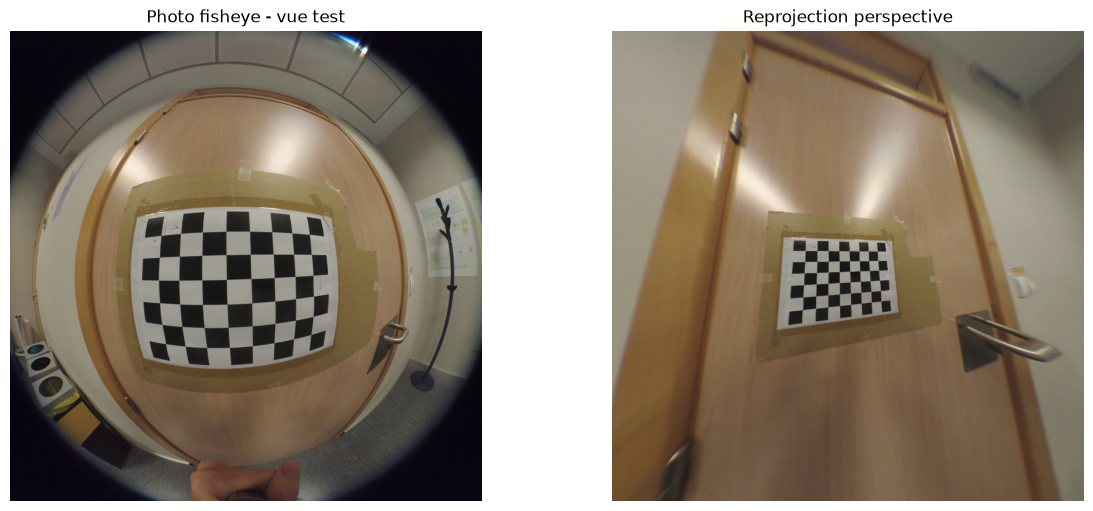

Paramètres enregistrés pour les images réduites, pas pour les originaux.


In [37]:
i = test_ids[0]
K_view = cv2.fisheye.estimateNewCameraMatrixForUndistortRectify(K_real, D_real, size_real, np.eye(3), balance=0)
map_x, map_y = cv2.fisheye.initUndistortRectifyMap(K_real, D_real, np.eye(3), K_view, size_real, cv2.CV_32FC1)
rectified = cv2.remap(photos[i], map_x, map_y, cv2.INTER_LINEAR)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, image, title in zip(axes, [photos[i], rectified], ["Photo fisheye - vue test", "Reprojection perspective"]):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.show()
np.savez(REAL_DIR / "calibration.npz", K=K_real, D=D_real, image_size=size_real,
         train_names=np.array(kept_names)[train_ids], test_names=np.array(kept_names)[test_ids], commit=COMMIT)
print("Paramètres enregistrés pour les images réduites, pas pour les originaux.")

### Ce que l'on peut conclure

Dans l'exécution fournie : **0,58 px** de RMSE en calibration et **0,53 px** au test ; **96,7 %** des coins test sont à moins de 1 px, et 95 % à moins d'environ **0,93 px**. La meilleure vue test est à environ **0,34 px**, la moins bonne à **0,72 px**. Quelques écarts dépassent donc 1 px malgré une moyenne favorable. Les valeurs peuvent varier légèrement selon la version d'OpenCV.

Les statistiques et les deux recadrages permettent de juger la cohérence **en pixels** du modèle sur ce jeu. Un faible résidu test est encourageant, mais ne mesure ni l'erreur de profondeur ni la précision de chaque coefficient : les poses test sont réestimées et il n'existe pas de vérité terrain intrinsèque ici.

Les erreurs restantes peuvent venir de la détection, de la planéité du damier, de l'hypothèse d'un point principal centré ou du modèle radial. Une seconde acquisition indépendante, plus de coins en périphérie et un contrôle de la mire seraient nécessaires avant d'utiliser cette calibration pour la navigation du robot.

Les paramètres enregistrés correspondent aux photos réduites. Un simple changement de résolution met à l'échelle les deux premières lignes de $K$ ; $D$ reste inchangé. Chaque caméra du banc devra être calibrée, puis leur pose relative estimée pour la stéréovision.